Dataset shape: (303, 14)
First 5 rows:
    age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   63    1   1       145   233    1        2      150      0      2.3      3   
1   67    1   4       160   286    0        2      108      1      1.5      2   
2   67    1   4       120   229    0        2      129      1      2.6      2   
3   37    1   3       130   250    0        0      187      0      3.5      3   
4   41    0   2       130   204    0        2      172      0      1.4      1   

    ca  thal  num  
0  0.0   6.0    0  
1  3.0   3.0    2  
2  2.0   7.0    1  
3  0.0   3.0    0  
4  0.0   3.0    0  
Missing values per column:
 age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64
Class distribution:
 num
0    160
1     54
2     35
3     35
4     13
Name: count, dtype: int64


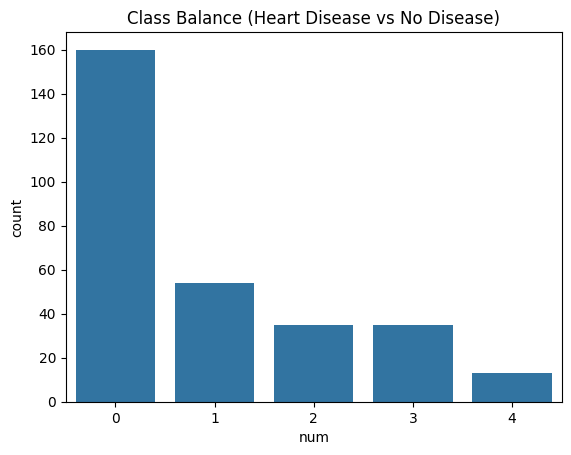

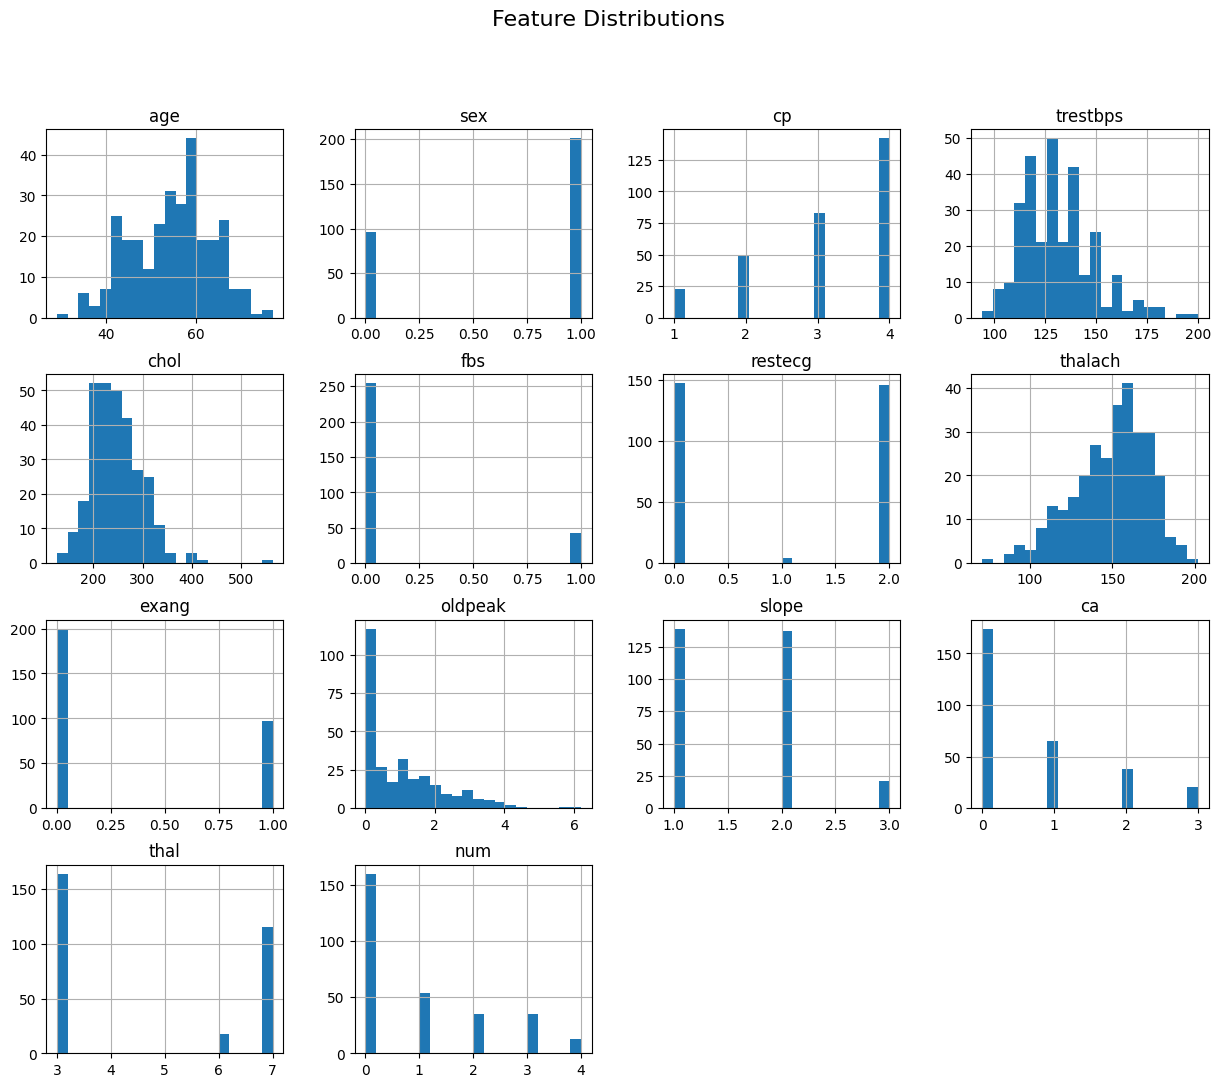

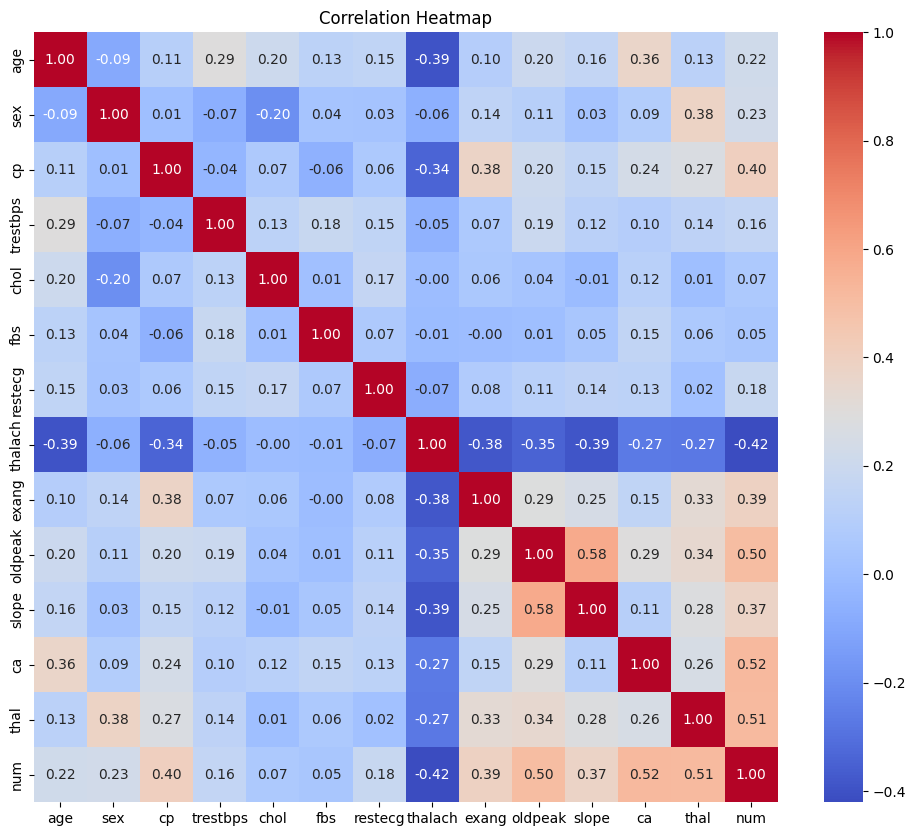

Statistical Summary:
               age         sex          cp    trestbps        chol         fbs  \
count  297.000000  297.000000  297.000000  297.000000  297.000000  297.000000   
mean    54.542088    0.676768    3.158249  131.693603  247.350168    0.144781   
std      9.049736    0.468500    0.964859   17.762806   51.997583    0.352474   
min     29.000000    0.000000    1.000000   94.000000  126.000000    0.000000   
25%     48.000000    0.000000    3.000000  120.000000  211.000000    0.000000   
50%     56.000000    1.000000    3.000000  130.000000  243.000000    0.000000   
75%     61.000000    1.000000    4.000000  140.000000  276.000000    0.000000   
max     77.000000    1.000000    4.000000  200.000000  564.000000    1.000000   

          restecg     thalach       exang     oldpeak       slope          ca  \
count  297.000000  297.000000  297.000000  297.000000  297.000000  297.000000   
mean     0.996633  149.599327    0.326599    1.055556    1.602694    0.676768   
std  

In [9]:
# ============================
# 1. Data Acquisition
# ============================
from ucimlrepo import fetch_ucirepo
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Fetch dataset from UCI ML Repository
heart_disease = fetch_ucirepo(id=45)

# Features and target
X = heart_disease.data.features
y = heart_disease.data.targets

# Combine into single DataFrame
df = pd.concat([X, y], axis=1)

print("Dataset shape:", df.shape)
print("First 5 rows:\n", df.head())

# ============================
# 2. Cleaning & Preprocessing
# ============================
# Check missing values
print("Missing values per column:\n", df.isnull().sum())

# Drop rows with missing values (or impute if needed)
df = df.dropna()

# Encode categorical variables if any are non-numeric
categorical_cols = df.select_dtypes(include=['object']).columns
df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# ============================
# 3. Exploratory Data Analysis
# ============================

# Class balance
print("Class distribution:\n", df['num'].value_counts())

sns.countplot(x='num', data=df)
plt.title("Class Balance (Heart Disease vs No Disease)")
plt.show()

# Histograms for all features
df.hist(figsize=(15,12), bins=20)
plt.suptitle("Feature Distributions", fontsize=16)
plt.show()

# Correlation heatmap
plt.figure(figsize=(12,10))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

# ============================
# 4. Statistical Summary
# ============================
print("Statistical Summary:\n", df.describe())


In [12]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score

X = df.drop('num', axis=1)
y = df['num']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Logistic Regression
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train, y_train)
y_pred_lr = log_reg.predict(X_test)
print("Logistic Regression:\n", classification_report(y_test, y_pred_lr))

# Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
print("Random Forest:\n", classification_report(y_test, y_pred_rf))

# Multiclass ROC-AUC using One-vs-Rest (ovr) strategy
print("ROC-AUC Logistic (OVR):", roc_auc_score(y_test, log_reg.predict_proba(X_test), multi_class='ovr'))
print("ROC-AUC RF (OVR):", roc_auc_score(y_test, rf.predict_proba(X_test), multi_class='ovr'))

Logistic Regression:
               precision    recall  f1-score   support

           0       0.79      0.94      0.86        36
           1       0.17      0.11      0.13         9
           2       0.50      0.20      0.29         5
           3       0.17      0.14      0.15         7
           4       0.00      0.00      0.00         3

    accuracy                           0.62        60
   macro avg       0.32      0.28      0.29        60
weighted avg       0.56      0.62      0.58        60

Random Forest:
               precision    recall  f1-score   support

           0       0.80      0.97      0.88        36
           1       0.00      0.00      0.00         9
           2       0.17      0.20      0.18         5
           3       0.00      0.00      0.00         7
           4       0.00      0.00      0.00         3

    accuracy                           0.60        60
   macro avg       0.19      0.23      0.21        60
weighted avg       0.49      0.60      

In [16]:
!pip install mlflow --quiet

import mlflow
import mlflow.sklearn
from sklearn.metrics import roc_auc_score

mlflow.set_experiment("HeartDiseasePrediction")

with mlflow.start_run(run_name="LogisticRegression"):
    mlflow.log_param("model", "LogisticRegression")
    roc_auc_lr = roc_auc_score(y_test, log_reg.predict_proba(X_test), multi_class='ovr')
    mlflow.log_metric("roc_auc", roc_auc_lr)
    mlflow.sklearn.log_model(log_reg, "model")

with mlflow.start_run(run_name="RandomForest"):
    mlflow.log_param("model", "RandomForest")
    roc_auc_rf = roc_auc_score(y_test, rf.predict_proba(X_test), multi_class='ovr')
    mlflow.log_metric("roc_auc", roc_auc_rf)
    # Trusting the scikit-learn tree structure to bypass the skops safety check
    mlflow.sklearn.log_model(rf, "model", skops_trusted_types=["sklearn.tree._tree.Tree"])

2026/10/20 15:40:49 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/20 15:40:55 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Model Packaging

In [17]:
import joblib
joblib.dump(rf, "model.pkl")

['model.pkl']

In [19]:
%%writefile requirements.txt
pandas
numpy
scikit-learn
mlflow
flask
pytest

Writing requirements.txt


TEST Files

In [20]:
import pandas as pd

def test_data_load():
    df = pd.read_csv("heart.csv")
    assert not df.empty
    assert "target" in df.columns

In [21]:
from flask import Flask, request, jsonify
import joblib
import numpy as np

app = Flask(__name__)
model = joblib.load("model.pkl")

@app.route("/predict", methods=["POST"])
def predict():
    data = request.json["features"]
    prediction = model.predict([data])[0]
    confidence = max(model.predict_proba([data])[0])
    return jsonify({"prediction": int(prediction), "confidence": confidence})

if __name__ == "__main__":
    app.run(host="0.0.0.0", port=5000)

 * Serving Flask app '__main__'
 * Debug mode: off


INFO:werkzeug:WARNING: This is a development server. Do not use it in a production deployment. Use a production WSGI server instead.
 * Running on all addresses (0.0.0.0)
 * Running on http://127.0.0.1:5000
 * Running on http://172.28.0.12:5000
INFO:werkzeug:Press CTRL+C to quit


```markdown
## Project Setup: Directory Structure

We will start by programmatically creating the workspace directory structure for our structured MLOps pipeline.
```

In [ ]:
import os

# Create directory structure
os.makedirs("heart_disease_mlops/data", exist_ok=True)
os.makedirs("heart_disease_mlops/src", exist_ok=True)
os.makedirs("heart_disease_mlops/tests", exist_ok=True)

print("Created heart_disease_mlops/ directory structure successfully!")

```markdown
## Step 1: Raw Data Acquisition

We will download the raw dataset and save it as a local CSV in `data/heart.csv` to ensure reproducibility and provide a source file for unit tests.
```

In [ ]:
from ucimlrepo import fetch_ucirepo
import pandas as pd

# Fetch dataset
heart_disease = fetch_ucirepo(id=45)
X = heart_disease.data.features
y = heart_disease.data.targets
df = pd.concat([X, y], axis=1)

# Save locally
df.to_csv("heart_disease_mlops/data/heart.csv", index=False)
print("Saved raw dataset to heart_disease_mlops/data/heart.csv")

```markdown
## Step 2: Data Preprocessing Module

Now, we modularize data cleaning, handling missing values, scaling, and splitting into a reusable python script `src/preprocess.py`.
```

In [ ]:
%%writefile heart_disease_mlops/src/preprocess.py
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

def load_and_clean_data(file_path):
    df = pd.read_csv(file_path)
    df = df.dropna()

    # Encode categorical variables if any non-numeric exist
    categorical_cols = df.select_dtypes(include=['object']).columns
    df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)
    return df

def prepare_splits(df, target_col='num', test_size=0.2, random_state=42):
    X = df.drop(target_col, axis=1)
    y = df[target_col]

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    X_train, X_test, y_train, y_test = train_test_split(
        X_scaled, y, test_size=test_size, random_state=random_state
    )
    return X_train, X_test, y_train, y_test, scaler

```markdown
## Step 3: Model Training and Logging Module

Let's write `src/train.py` to handle MLflow experiment tracking, model training, evaluation metrics, and persisting the final trained artifact.
```

In [ ]:
%%writefile heart_disease_mlops/src/train.py
import mlflow
import mlflow.sklearn
import joblib
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, classification_report
from preprocess import load_and_clean_data, prepare_splits

def train_pipeline():
    # Load and preprocess
    df = load_and_clean_data("heart_disease_mlops/data/heart.csv")
    X_train, X_test, y_train, y_test, scaler = prepare_splits(df)

    # Set up MLflow tracking
    mlflow.set_experiment("HeartDiseasePrediction")

    # 1. Logistic Regression Run
    with mlflow.start_run(run_name="LogisticRegression"):
        log_reg = LogisticRegression(max_iter=1000)
        log_reg.fit(X_train, y_train)
        y_pred = log_reg.predict(X_test)
        roc_auc = roc_auc_score(y_test, log_reg.predict_proba(X_test), multi_class='ovr')

        mlflow.log_param("model_type", "LogisticRegression")
        mlflow.log_metric("roc_auc_ovr", roc_auc)
        mlflow.sklearn.log_model(log_reg, "model")
        print(f"Logistic Regression OVR ROC-AUC: {roc_auc:.4f}")

    # 2. Random Forest Run
    with mlflow.start_run(run_name="RandomForest"):
        rf = RandomForestClassifier(n_estimators=100, random_state=42)
        rf.fit(X_train, y_train)
        y_pred = rf.predict(X_test)
        roc_auc = roc_auc_score(y_test, rf.predict_proba(X_test), multi_class='ovr')

        mlflow.log_param("model_type", "RandomForest")
        mlflow.log_metric("roc_auc_ovr", roc_auc)
        mlflow.sklearn.log_model(rf, "model", skops_trusted_types=["sklearn.tree._tree.Tree"])
        print(f"Random Forest OVR ROC-AUC: {roc_auc:.4f}")

        # Export best model as production pickle
        joblib.dump(rf, "heart_disease_mlops/src/model.pkl")
        # Export scaler for inference preprocessing consistency
        joblib.dump(scaler, "heart_disease_mlops/src/scaler.pkl")
        print("Saved best model artifacts successfully.")

if __name__ == "__main__":
    # Modify path so script can find preprocess relative import
    import sys
    sys.path.append("heart_disease_mlops/src")
    train_pipeline()

```markdown
## Step 4: Robust Testing Suite

We separate unit tests into `tests/test_pipeline.py`. Running these tests ensures data assumptions hold true and predictions scale correctly.
```

In [ ]:
%%writefile heart_disease_mlops/tests/test_pipeline.py
import os
import pandas as pd
import sys
sys.path.append("heart_disease_mlops/src")
from preprocess import load_and_clean_data

def test_data_load():
    file_path = "heart_disease_mlops/data/heart.csv"
    assert os.path.exists(file_path), "Raw dataset file does not exist."

    df = pd.read_csv(file_path)
    assert not df.empty, "Dataframe should not be empty."
    assert "num" in df.columns, "Target label column 'num' must be in dataset."

def test_preprocessing():
    file_path = "heart_disease_mlops/data/heart.csv"
    cleaned_df = load_and_clean_data(file_path)
    assert cleaned_df.isnull().sum().sum() == 0, "Cleaned dataset must contain no null values."

```markdown
## Step 5: Web API Server (Flask)

We decouple the Flask Web Server into `src/app.py` so that it doesn't block the notebook execution thread and can be executed via terminal commands or Docker.
```

In [ ]:
%%writefile heart_disease_mlops/src/app.py
from flask import Flask, request, jsonify
import joblib
import numpy as np
import os

app = Flask(__name__)

# Adjust file paths for modular structure
MODEL_PATH = os.path.join(os.path.dirname(__file__), "model.pkl")
SCALER_PATH = os.path.join(os.path.dirname(__file__), "scaler.pkl")

if os.path.exists(MODEL_PATH) and os.path.exists(SCALER_PATH):
    model = joblib.load(MODEL_PATH)
    scaler = joblib.load(SCALER_PATH)
else:
    model, scaler = None, None

@app.route("/predict", methods=["POST"])
def predict():
    if not model or not scaler:
         return jsonify({"error": "Model or scaler artifacts missing on server."}), 500

    data = request.json["features"]

    # Ensure inputs are scaled to match training scale dimensions
    scaled_data = scaler.transform([data])

    prediction = model.predict(scaled_data)[0]
    confidence = max(model.predict_proba(scaled_data)[0])
    return jsonify({"prediction": int(prediction), "confidence": float(confidence)})

if __name__ == "__main__":
    app.run(host="0.0.0.0", port=5000)

```markdown
## Step 6: Requirements Specification

We update our project dependencies specifically inside our deployment root directory.
```

In [ ]:
%%writefile heart_disease_mlops/requirements.txt
pandas
numpy
scikit-learn
mlflow
flask
pytest
joblib
ucimlrepo

```markdown
## Execute the Pipeline & Verification

Now, let's run the model training script and execute the unit tests via `pytest` to guarantee everything is operating seamlessly.
```

In [ ]:
# Run the end-to-end training and artifact generation pipeline
!PYTHONPATH=heart_disease_mlops/src python heart_disease_mlops/src/train.py

In [ ]:
# Execute pytest over our modular test directory
!pytest heart_disease_mlops/tests/